In [1]:
#Very first step is to import these modules and libraries into the satprocessing kernel
import numpy as np
import dask as ds
import earthaccess as ea
import xarray as xr
import sys
import matplotlib.pyplot as plt
import requests
import pandas as pd
import PyCO2SYS as pyco2
import cartopy
from shapely.ops import unary_union
import cartopy.feature as cfeature
from datetime import date
from scipy.spatial import KDTree
from datasets import Dataset
print("module import success")

import sys
sys.path.append(r'C:\\Users\\edmund.gable\\Documents\\Hollings_2026\\RESOURCES\\python\\utilities\\bootstrap\\')
print("path import success")

import pprint
from environment import bootstrap_environment  
pprint.pprint(bootstrap_environment(preferred="edmund_gable"))
print("success")

from utilities.bootstrap.environment import bootstrap_environment
env = bootstrap_environment(preferred="edmund.gable")
env
print("utilities import success")

#Before this next step, install the library 'resource': conda install -c conda-forge resource
from utilities import get_dates, get_source_file_dates, find_text
find_text("stats")

from utilities import get_prod_files 
get_prod_files("DO", period="DOY")
#"DOY" is climatological 'day of year
#'W' is climatological weekly files

from pathlib import Path

root = Path(r"C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026")
raw_data = Path(r"C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026\data\Raw_Data")
model_data = Path(r"Z:\MOM6\Hindcasts")
processed_data=Path(r"C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026\data\Processed_Data\comparison")




c:\Users\edmund.gable\.conda\envs\satprocessing\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


module import success
path import success
⚠ Unrecognized preferred label 'edmund_gable'. Valid options: ['NECMAC04363461.local', 'nefscsatdata', 'guihyde', 'Mac.localdomain', 'gdavis', 'egable']
{'dataset_path': WindowsPath('C:/Users/edmund.gable/Documents/Hollings_2026/DATASETS'),
 'hostname': 'NECL04363598',
 'lookuptable_path': WindowsPath('C:/Users/edmund.gable/Documents/Hollings_2026/RESOURCES/workflow_resources/lookuptables'),
 'metadata_path': WindowsPath('C:/Users/edmund.gable/Documents/Hollings_2026/RESOURCES/workflow_resources/metadata'),
 'project_root': WindowsPath('C:/Users/edmund.gable/Documents/Hollings_2026/RESOURCES/python'),
 'python_path': WindowsPath('C:/Users/edmund.gable/Documents/Hollings_2026/RESOURCES/python'),
 'satlogs_path': WindowsPath('C:/Users/edmund.gable/Documents/Hollings_2026/RESOURCES/logs/satprocessing'),
 'timestamp': datetime.datetime(2026, 7, 13, 8, 36, 35, 49484),
 'utilities_path': WindowsPath('C:/Users/edmund.gable/Documents/Hollings_2026/RESO

In [2]:
# 1. Establish the Master Blueprint Grid Layout
dsg = xr.open_dataset(r"Z:\MOM6\V0.0\SOURCE\NES_9KM_HINDCAST\ARAG\CEFI-ARAG-HINDCAST-20070101.nc")
ny, nx = len(dsg.lat), len(dsg.lon)
grid_id_matrix = np.array([[f"{y},{x}" for x in range(nx)] for y in range(ny)], dtype=str)
grid_ds = dsg.assign_coords(grid_id=(['lat', 'lon'], grid_id_matrix))

In [3]:

def classify_OA(df, OA_column, status_col):
    classified_df=df.copy()
    classified_df.loc[classified_df[OA_column]>3.0, status_col]='Optimal'
    classified_df.loc[classified_df[OA_column]>1.4, status_col]='Saturated'
    classified_df.loc[classified_df[OA_column]<1.4, status_col]='Suboptimal'
    classified_df.loc[classified_df[OA_column]<1.19, status_col]='Atlantic Cod threshold surpassed'
    classified_df.loc[classified_df[OA_column]<1.1, status_col]='Atlantic Sea Scallop threshold surpassed'
    classified_df.loc[classified_df[OA_column]<1, status_col]='Critical threshold surpassed'
    classified_df=classified_df.reset_index()
    return classified_df

    
def open_file(file):
    ds = xr.open_dataset(file)
    df = ds.to_dataframe().reset_index()
    print("Available flattened columns:", df.columns.to_list())
    return df



In [ ]:
def prepare_df(df, OA_column, id_col, obs_depth_col, bottom_depth_col, lat_col, lon_col, time_col, mom6_grid_df):
    df = df.dropna(subset=[OA_column])

    depth_mismatch = abs(df[obs_depth_col] - df[bottom_depth_col]).astype(float)
    max_mismatch = np.minimum(0.1 * df[bottom_depth_col], 20)
    df_filtered = df[depth_mismatch < max_mismatch].copy()

    df_filtered["matched_time"] = pd.to_datetime(df_filtered[time_col]).dt.normalize() + pd.Timedelta(hours=12)
   
    pt_lats = xr.DataArray(df_filtered[lat_col], dims='points')
    pt_lons = xr.DataArray(df_filtered[lon_col], dims='points')

    nearest_grid = grid_ds.sel(lat=pt_lats, lon=pt_lons, method='nearest')

    df_filtered['matched_lat'] = nearest_grid.lat.values
    df_filtered['matched_lon'] = nearest_grid.lon.values
    df_filtered['grid_id'] = nearest_grid.grid_id.values.astype(str)
    df = df_filtered

    rename_dict = {
        OA_column: "saturated_aragonite",
        id_col: "id",
        obs_depth_col: "obs_depth",
        bottom_depth_col: "bottom_depth",
        lat_col: "lat",
        lon_col: "lon",
        time_col: "time",
    }
    df = df.rename(columns=rename_dict)
    
    agg_rules = {
        "saturated_aragonite": "mean",    
        "obs_depth": "mean",           
        "bottom_depth": "mean",        
        "lat": "mean",                 
        "lon": "mean",                 
        "id": "first",                 
        "matched_lat": "first",        
        "matched_lon": "first"         
    }
      
    df = df.groupby(['matched_time', 'grid_id'], as_index=False).agg(agg_rules)
    df = classify_OA(df, 'saturated_aragonite', 'arag_status')
    
    requested_columns = [
        "id", "lat", "lon", "obs_depth", "bottom_depth",
        "saturated_aragonite", "arag_status", "grid_id",
        "matched_time", "matched_lat", "matched_lon"
    ]
    return df[requested_columns]


def prepare_df_no_depth(df, OA_col, id_col, lat_col, lon_col, time_col, mom6_grid_df):
    df_filtered = df.dropna(subset=[OA_col]).copy()

    df_filtered = df_filtered.reset_index(drop=True)
    df_filtered["matched_time"] = pd.to_datetime(df_filtered[time_col]).dt.normalize() + pd.Timedelta(hours=12)
     
    pt_lats = xr.DataArray(df_filtered[lat_col], dims='points')
    pt_lons = xr.DataArray(df_filtered[lon_col], dims='points')

    nearest_grid = grid_ds.sel(lat=pt_lats, lon=pt_lons, method='nearest')

    df_filtered['matched_lat'] = nearest_grid.lat.values
    df_filtered['matched_lon'] = nearest_grid.lon.values
    raw_ids = nearest_grid.grid_id.values.astype(str)
    
    # 2. Strip any negative signs and ensure a clean space after the separator
    clean_ids = [str(rid).replace('-', '') for rid in raw_ids]
    
    # 3. Save it to the dataframe
    df_filtered['grid_id'] = clean_ids
    # FIX: Cleaned up the assignment typo and converted cleanly to text string arrays
    df_filtered['grid_id'] = nearest_grid.grid_id.values.astype(str)

    rename_dict = {
        OA_col: "saturated_aragonite",
        id_col: "id",
        lat_col: "lat",
        lon_col: "lon",
        time_col: "time",
    }
    df_mapped = df_filtered.rename(columns=rename_dict)
    
    agg_rules = {
        "saturated_aragonite": "mean",     
        "lat": "mean",                  
        "lon": "mean",                  
        "id": "first",                  
        "matched_lat": "first",         
        "matched_lon": "first"          
    }
    
    # FIX: added as_index=False so pandas doesn't convert grid_id into a MultiIndex row layout
    df_agg = df_mapped.groupby(['matched_time', 'grid_id'], as_index=False).agg(agg_rules)
    df_classified = classify_OA(df_agg, 'saturated_aragonite', 'arag_status')
    
    requested_columns = [
        "id", "lat", "lon", "saturated_aragonite", "arag_status",  
        "grid_id", "matched_time", "matched_lat", "matched_lon"
    ]
    return df_classified[requested_columns]



In [3]:

def load_combined_OA_mom6_data(df, model_data, grid_ds=None):
    model_data = Path(model_data)
    df_list = []
    
    df = df.copy()
    # Ensure standard datetime formats for matching
    df['matched_time'] = pd.to_datetime(df['matched_time'])
    df['lat'] = df['matched_lat']
    df['lon'] = df['matched_lon']
    
    unique_dates = df['matched_time'].dt.normalize().unique()
    print(f"Processing {len(unique_dates)} unique dates...")
    
    for center_date in unique_dates:
        # 1. Target a 3-day window around the center date
        target_days = [center_date - pd.Timedelta(days=1), center_date, center_date + pd.Timedelta(days=1)]
        daily_slices = []
        
        # Consistent file names across loops
        ion_file_name = "ocean_cobalt_daily_2d.19930101-20231231.btm_co3_ion.nc"
        sol_file_name = "ocean_cobalt_daily_2d.19930101-20231231.btm_co3_sol_arag.nc"
        
        ion_target_file_path = model_data / ion_file_name
        sol_target_file_path = model_data / sol_file_name

        if ion_target_file_path.exists() and sol_target_file_path.exists():
            # Open lazily without bringing 30GB into RAM
            ion_ds = xr.open_dataset(ion_target_file_path) 
            sol_ds = xr.open_dataset(sol_target_file_path)
            
            for d in target_days:
                try:
                    # Slice the exact day from both datasets lazily
                    ion_day = ion_ds['btm_co3_ion'].sel(time=d, method='nearest')
                    sol_day = sol_ds['btm_co3_sol_arag'].sel(time=d, method='nearest')
                    
                    # Compute aragonite saturation state lazily via vector division
                    arag_day = ion_day / sol_day
                    
                    # Compute/load ONLY this day's 2D slice into memory
                    daily_slices.append(arag_day.load())
                except KeyError:
                    # Catches dates out of the NetCDF time bound range gracefully
                    continue
                    
        if not daily_slices:
            continue
            
        # Combine the 3 days into a small 3D local in-memory cube
        ds_window = xr.concat(daily_slices, dim='time')
        
        if grid_ds is not None:
            # Match MOM6 grid array dimensions if a grid file mapping is passed
            ds_window = ds_window.assign_coords(grid_id=(['yh', 'xh'], grid_ds.grid_id.values))
            ds_window['grid_id'] = ds_window['grid_id'].astype(str)
            
        # Map back to MOM6 coordinate designations (yh, xh)
        yh_arr, xh_arr = ds_window.yh.values, ds_window.xh.values
        df_day = df[df['matched_time'].dt.normalize() == center_date]
        
        # 2. Extract space-time metrics for each observation point on this day
        for idx, row in df_day.iterrows():
            # Find closest center indices
            yh_idx = int(np.argmin(np.abs(yh_arr - row['lat'])))
            xh_idx = int(np.argmin(np.abs(xh_arr - row['lon'])))
            
            # Slice out the 3x3 horizontal window from the combined aragonite window
            yh_slice = slice(max(0, yh_idx - 1), yh_idx + 2)
            xh_slice = slice(max(0, xh_idx - 1), xh_idx + 2)
            
            cube_3x3x3 = ds_window.isel(yh=yh_slice, xh=xh_slice)
            arag_cube = cube_3x3x3.values 
            
            if np.all(np.isnan(arag_cube)):
                continue
                
            # --- EXACT SPATIOTEMPORAL MATCH ---
            time_deltas = np.abs(pd.to_datetime(cube_3x3x3.time.values) - center_date)
            t_exact_idx = int(np.argmin(time_deltas))
            
            y_exact_idx = int(np.argmin(np.abs(cube_3x3x3.yh.values - row['lat'])))
            x_exact_idx = int(np.argmin(np.abs(cube_3x3x3.xh.values - row['lon'])))
            
            exact_match_val = float(arag_cube[t_exact_idx, y_exact_idx, x_exact_idx])

            # --- EXTRACT RAW ION AND SOL VALUES FOR EXACT MATCH ---
            # We look at the exact same spatial/temporal indices in the daily datasets
            exact_time_str = str(cube_3x3x3.time.values[t_exact_idx])
            exact_yh = cube_3x3x3.yh.values[y_exact_idx]
            exact_xh = cube_3x3x3.xh.values[x_exact_idx]
            
            # Pull single scalar values directly out of the open handles
            exact_ion_val = float(ion_ds['btm_co3_ion'].sel(time=exact_time_str, yh=exact_yh, xh=exact_xh, method='nearest').values)
            exact_sol_val = float(sol_ds['btm_co3_sol_arag'].sel(time=exact_time_str, yh=exact_yh, xh=exact_xh, method='nearest').values)

            # --- CLOSEST 3x3x3 NEIGHBOR MATCH ---
            abs_diff = np.abs(arag_cube - row['saturated_aragonite'])
            flat_idx = np.nanargmin(abs_diff) 
            grid_t, grid_y, grid_x = np.unravel_index(flat_idx, arag_cube.shape)
            
            closest_val = float(arag_cube[grid_t, grid_y, grid_x])
            closest_lat = float(cube_3x3x3.yh.values[grid_y])
            closest_lon = float(cube_3x3x3.xh.values[grid_x])
            closest_time = pd.Timestamp(cube_3x3x3.time.values[grid_t])
            
            # Extract Grid ID
            if 'grid_id' in cube_3x3x3.coords:
                text = str(cube_3x3x3.grid_id.values[grid_y, grid_x]).replace('-', '')
                sep = ';' if ';' in text else ','
                y_val, x_val = text.split(sep)
                closest_grid_id = f"({y_val.strip()}{sep} {x_val.strip()})"
            else:
                closest_grid_id = f"({closest_lat}, {closest_lon})"
                
            # --- MERGE INTO DATA DICTIONARY ---
            matched_row = row.to_dict()
            matched_row.update({
                "exact_model_val": exact_match_val,
                "model_btm_ion": exact_ion_val,       # <--- NEW COLUMN
                "model_btm_sol": exact_sol_val,       # <--- NEW COLUMN
                "cube_mean": float(np.nanmean(arag_cube)),
                "cube_std": float(np.nanstd(arag_cube)),
                "cube_min": float(np.nanmin(arag_cube)),
                "cube_max": float(np.nanmax(arag_cube)),
                "closest_model_val": closest_val,
                "closest_grid_id": closest_grid_id,
                "closest_lat": closest_lat,
                "closest_lon": closest_lon,
                "closest_time": closest_time
            })
            df_list.append(matched_row)
            
    return pd.DataFrame(df_list).reset_index(drop=True)

In [2]:

def delta_difference(df):
    # 1. Clear out rows missing model data OR real-world observations up front
    df = df.dropna(subset=['closest_model_val', 'exact_model_val', 'saturated_aragonite']).copy()
    
    # 2. Calculate point-by-point delta difference
    df['delta_difference_point'] = df['exact_model_val'] - df['saturated_aragonite']
    df['delta_difference_grid'] = df['closest_model_val'] - df['saturated_aragonite']
    print(f"Mean of delta difference between model 3x3x3 grid data and observational data is: {np.nanmean(df['delta_difference_grid']):4f}")
    print(f"Mean of delta difference between model exact grid data and observational data is: {np.nanmean(df['delta_difference_point']):4f}")
    # 3. Calculate Global Dataset RMSE (Using numpy across the board for safety)
    global_rmse_grid = np.sqrt(np.nanmean(df['delta_difference_grid'] ** 2))
    print(f"Global RMSE (3x3x3 grid vs obs): {global_rmse_grid:.4f}")
    
    # Exact Match RMSE (Safely handles any land-masked exact points)
    global_rmse_exact = np.sqrt(np.nanmean(df['delta_difference_point'] ** 2))
    
    # Count how many non-nan exact points actually went into the math
    num_valid_exact = df['delta_difference_point'].notna().sum()
    print(f"Global RMSE (Exact point vs Obs): {global_rmse_exact:.4f}")
    print(f"-> Calculated using {num_valid_exact} valid exact points (out of {len(df)} total pairs).")


    # 4. Calculate Local Z-score (point relative to its 3x3x3 grid)
    # Note: Added 1e-9 to prevent division-by-zero if a cube std is 0 
    df['local_z_score'] = (df['cube_mean'] - df['saturated_aragonite']) / (df['cube_std'] + 1e-9)
    
    # 5. Calculate Global Statistics
    closest_mean = df['closest_model_val'].mean()
    obs_mean=df['saturated_aragonite'].mean()
    
    # Combined variance formula: mean of variances + variance of means
    mean_of_variance=(df['cube_std']**2).mean()
    variance_of_means=df['cube_mean'].var()

    global_variance = mean_of_variance + variance_of_means
    global_std = np.sqrt(global_variance)
    closest_std = df['closest_model_val'].std()
    global_mean = df['cube_mean'].mean()
    print(f"Calculated Observational Mean: {obs_mean:.4f}")
    print(f"Calculated Closest Model Mean: {closest_mean:.4f}")
    print(f"Calculated Global Mean: {global_mean:.4f}")
    print(f"Calculated Global Std Dev: {global_std:.4f}")
    print(f"Calculated Closest Model Std Dev: {closest_std:.4f}")

    over_est_pct=(df['delta_difference_grid']>0).mean()*100
    under_est_pct=(df['delta_difference_grid']<0).mean()*100
    print(f"Model grid overestimates the data {over_est_pct} percent of the time")
    print(f"Model grid underestimates the data {under_est_pct} percent of the time")
    avg_overestimation = df[df['delta_difference_grid'] > 0]['delta_difference_grid'].mean()
    avg_underestimation = df[df['delta_difference_grid'] < 0]['delta_difference_grid'].mean()

    print(f"When overestimating, the average excess aragonite is: {avg_overestimation:.4f}")
    print(f"When underestimating, the average deficit aragonite is: {avg_underestimation:.4f}")

    # Calculate the standard deviation of your real-world observations
    obs_std = df['saturated_aragonite'].std()

    print(f"Real-World Observational STD: {obs_std:.4f}")
    print(f"Model Global STD: {global_std:.4f}")
    
# Compare them
    std_ratio = global_std / obs_std
    print(f"Model-to-Observation Variance Ratio: {std_ratio:.2f}")
    print(f"RSR of Model is: {global_rmse_grid/obs_std:.4f}")
    # 6. Calculate Global Z-score for each observational point
    df['global_z_score'] = (df['saturated_aragonite'] - closest_mean) / closest_std
    
    ###Must run classify_arag on model combined specifically
    stressed_obs = df[df['saturated_aragonite'] <1.4]
    stressed_mod=df[df['closest_model_val'] <1.4]
    critical_obs=df[df['saturated_aragonite'] <1]
    critical_mod=df[df['closest_model_val']<1]
    obs_is_stressed = df['saturated_aragonite'] < 1.4
    mod_is_stressed = df['closest_model_val'] < 1.4
    
    if len(stressed_obs) > 0:
        # 2. Calculate how often the model status matches the observation status exactly
        status_matches = (obs_is_stressed & mod_is_stressed).sum()
        match_rate = (status_matches / max(len(stressed_obs), 1)) * 100
        match_precision = (status_matches / max(len(stressed_mod), 1)) * 100
        false_positive = (mod_is_stressed & ~obs_is_stressed).sum()
        
        # False Negative: Obs saw stress (< 1.4), but Model says normal (>= 1.4)
        false_negative = (obs_is_stressed & ~mod_is_stressed).sum()
        
        fpp = (false_positive / max(len(stressed_mod), 1)) * 100
        fnp = (false_negative / max(len(stressed_obs), 1)) * 100
        # Missed Critical: Obs was critical (< 1) but Model failed to see it as critical (>= 1)
        missed_critical = ((df['saturated_aragonite'] < 1) & ~(df['closest_model_val'] < 1)).sum()
        fcp = (missed_critical / max(len(critical_obs), 1)) * 100

        print(f"\n===========================================================")
        print(f"ARAGONITE STATUS MATCH METRICS (Thresholds: Stressed < 1.4, Critical < 1.0)")
        print(f"===========================================================")
        print(f"Total observations showing stressed conditions: {len(stressed_obs)}")
        print(f"Total model outputs showing stressed conditions: {len(stressed_mod)}")
        print(f"Total observations showing critical threshold surpassed: {len(critical_obs)}")
        print(f"Total model outputs showing critical threshold surpassed: {len(critical_mod)}")
        print(f'False Positives: Of the {len(stressed_mod)} times the model predicted stress, {fpp:.2f}% were false alarms')
        print(f'False Negatives: Of the {len(stressed_obs)} times the observations detected stress, {fnp:.2f}% were missed by the model')
        print(f'Critical threshold surpassed: Of the {len(critical_obs)} times the observations detected acute dissolution, {fcp:.2f}% were missed by the model')
        print(f'Match Precision: Of the {len(stressed_mod)} times the model predicted stress, {match_precision:.2f}% were verified by observations')
        print(f"Overall Model Stress Sensitivity (Recall): {match_rate:.2f}%")
        print(f"-----------------------------------------------------------")
    return df

In [ ]:
ds=xr.open_dataset(r"Z:\MOM6\Retrospective Forecasts\climatology_ocean_daily_tob_1994_2023.nc")
df=ds.to_dataframe()
df

Combine Glider and Vessel OA data

In [6]:
Gliders=open_file(r"C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026\data\Raw_Data\Gliders\glider_based_bottom_OA_data_2019_2025.nc")
Gliders
Vessels=open_file()


Available flattened columns: ['time', 'deployment', 'lat', 'lon', 'depth', 'bottom_depth', 'pH_bottom', 'omega_bottom', 'temperature_bottom']


,time,deployment,lat,lon,depth,bottom_depth,pH_bottom,omega_bottom,temperature_bottom
0,2019-08-05 00:01:15.711111168,ru30-20190717T1812,39.809955,-73.212830,39.491982,43.0,7.8281,1.08,7.950000
1,2019-08-05 00:05:55.698529024,ru30-20190717T1812,39.810494,-73.214054,39.546547,43.0,7.8257,1.08,7.950000
2,2019-08-05 00:10:47.911289856,ru30-20190717T1812,39.811057,-73.215331,41.148884,43.0,7.8294,1.09,7.960000
3,2019-08-05 00:15:05.200000000,ru30-20190717T1812,39.811553,-73.216456,41.044708,43.0,7.8278,1.08,7.960000
4,2019-08-05 00:19:32.785124096,ru30-20190717T1812,39.812068,-73.217626,42.493248,43.0,7.8300,1.09,7.970000
...,...,...,...,...,...,...,...,...,...
134051,2025-08-11 14:30:33.000000000,ru39-20250716T1542,39.305976,-74.335720,12.836317,15.0,8.0142,2.69,23.660000
134052,2025-08-11 14:45:56.144999936,ru39-20250716T1542,39.305388,-74.335010,12.325262,15.0,8.0202,2.72,23.670000
134053,2025-08-11 14:46:08.020999936,ru39-20250716T1542,39.305386,-74.335017,12.196258,15.0,8.0215,2.72,23.670000
134054,2025-08-11 14:54:37.000000000,ru39-20250716T1542,39.305121,-74.334853,12.141679,15.0,8.0223,2.73,23.690001


In [15]:
mom6_grid_df = pd.read_csv(r"C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026\data\Index\MOM6_Grid_Extent.csv")

Gliders=open_file(r"C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026\data\Raw_Data\Gliders\glider_based_bottom_OA_data_2019_2025.nc")
Vessels=open_file(r"C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026\data\Raw_Data\Vessels\vessel_based_bottom_OA_data_2007_2024.nc")
Gliders['id']=Gliders['deployment']
Gliders.drop(columns=['deployment'], inplace=True)
Vessels['id']=Vessels['data_source']
Vessels.drop(columns=['data_source'], inplace=True)
Gliders=Gliders.reset_index()
Vessels=Vessels.reset_index()
Gliders['time'] = pd.to_datetime(Gliders['time'], errors='coerce')
Vessels=classify_OA(Vessels, 'omega_bottom', 'arag_status')
Gliders=classify_OA(Gliders, 'omega_bottom', 'arag_status')
merged_df = pd.concat([Gliders, Vessels], ignore_index=True)
print(merged_df.columns.to_list())
merged_df.to_csv(processed_data / 'OA_CONCAT.csv')



Available flattened columns: ['time', 'deployment', 'lat', 'lon', 'depth', 'bottom_depth', 'pH_bottom', 'omega_bottom', 'temperature_bottom']
Available flattened columns: ['time', 'data_source', 'cruise', 'obs_type', 'accession', 'lat', 'lon', 'depth', 'bottom_depth', 'pH_bottom', 'omega_bottom', 'temperature_bottom']
['level_0', 'index', 'time', 'lat', 'lon', 'depth', 'bottom_depth', 'pH_bottom', 'omega_bottom', 'temperature_bottom', 'id', 'arag_status', 'cruise', 'obs_type', 'accession']


In [ ]:
merged_df

In [16]:
mom6_grid_df = pd.read_csv(r"C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026\data\Index\MOM6_Grid_Extent.csv")
df=pd.read_csv(r"C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026\data\Processed_Data\comparison\OA_CONCAT.csv")
df["time"] = pd.to_datetime(df['time'])
dfp=prepare_df(df, 'omega_bottom', 'id', 'depth', 'bottom_depth', 'lat', 'lon', 'time', mom6_grid_df)
dfp.to_csv(processed_data / 'OA_Concat_prepared.csv')

C:\Users\edmund.gable\AppData\Local\Temp\ipykernel_13876\2005360664.py:2: DtypeWarning: Columns (0: obs_type) have mixed types. Specify dtype option on import or set low_memory=False.
  df=pd.read_csv(r"C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026\data\Processed_Data\comparison\OA_CONCAT.csv")


In [ ]:
df=load_combined_OA_mom6_data(dfp, model_data, grid_ds=None)
df

Processing 1047 unique dates...


,id,lat,lon,obs_depth,bottom_depth,saturated_aragonite,arag_status,grid_id,matched_time,matched_lat,...,model_btm_sol,cube_mean,cube_std,cube_min,cube_max,closest_model_val,closest_grid_id,closest_lat,closest_lon,closest_time
0,GOMECC1,42.476232,-68.995650,210.500000,230.000000,1.240000,Suboptimal,"318,167",2007-07-29 12:00:00,42.476232,...,0.000069,1.607655,0.002866,1.603342,1.612242,1.603342,"(42.44294738769531, -68.8800048828125)",42.442947,-68.880005,2007-07-30 12:00:00
1,GOMECC1,42.727184,-69.721731,275.900000,292.000000,1.230000,Suboptimal,"322,158",2007-07-29 12:00:00,42.727184,...,0.000069,1.611302,0.003581,1.605337,1.620797,1.605337,"(42.79616165161133, -69.83999633789062)",42.796162,-69.839996,2007-07-30 12:00:00
2,GOMECC1,40.029446,-69.963758,159.100000,164.000000,1.650000,Saturated,"279,155",2007-07-31 12:00:00,40.029446,...,0.000068,1.782211,0.142022,1.560402,1.936776,1.619879,"(39.97586441040039, -69.92001342773438)",39.975864,-69.920013,2007-08-01 12:00:00
3,GOMECC1,40.154922,-70.125109,118.000000,124.000000,1.730000,Saturated,"281,153",2007-07-31 12:00:00,40.154922,...,0.000067,1.811283,0.135974,1.522880,1.919483,1.756744,"(40.22064208984375, -70.07998657226562)",40.220642,-70.079987,2007-08-01 12:00:00
4,GOMECC1,40.280399,-70.205785,86.900000,95.000000,1.660000,Saturated,"283,152",2007-07-31 12:00:00,40.280399,...,0.000067,1.520768,0.116194,1.404049,1.818523,1.644944,"(40.22064208984375, -70.239990234375)",40.220642,-70.239990,2007-07-30 12:00:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5221,ru39-20250716T1542,39.276589,-74.320243,16.676913,17.375000,2.729167,Saturated,"267,101",2025-08-09 12:00:00,39.276589,...,0.000066,2.024154,0.063572,1.888307,2.096904,2.096904,"(39.23624801635742, -74.239990234375)",39.236248,-74.239990,2023-12-31 12:00:00
5222,ru39-20250716T1542,39.213851,-74.320243,17.589666,18.615385,2.508462,Saturated,"266,101",2025-08-10 12:00:00,39.213851,...,0.000066,2.068414,0.044706,1.978266,2.115983,2.115983,"(39.17425537109375, -74.239990234375)",39.174255,-74.239990,2023-12-31 12:00:00
5223,ru39-20250716T1542,39.276589,-74.320243,16.639061,17.380952,2.686667,Saturated,"267,101",2025-08-10 12:00:00,39.276589,...,0.000066,2.024154,0.063572,1.888307,2.096904,2.096904,"(39.23624801635742, -74.239990234375)",39.236248,-74.239990,2023-12-31 12:00:00
5224,ru39-20250716T1542,39.276589,-74.320243,15.163669,15.666667,2.715098,Saturated,"267,101",2025-08-11 12:00:00,39.276589,...,0.000066,2.024154,0.063572,1.888307,2.096904,2.096904,"(39.23624801635742, -74.239990234375)",39.236248,-74.239990,2023-12-31 12:00:00


In [ ]:

#final=classify_OA(df, 'closest_model_val', 'model_arag_status')
final=pd.read_csv(r"C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026\data\Processed_Data\comparison\OA_MOM6_3x3x3_comparison.csv")

final= delta_difference(final)


Mean of delta difference between model 3x3x3 grid data and observational data is: 0.311311
Mean of delta difference between model exact grid data and observational data is: 0.352042
Global RMSE (3x3x3 grid vs obs): 0.5021
Global RMSE (Exact point vs Obs): 0.5675
-> Calculated using 5222 valid exact points (out of 5226 total pairs).
Calculated Observational Mean: 1.5502
Calculated Model Global Mean: 1.9006
Calculated Global Std Dev: 0.3163
Model grid overestimates the data 80.99885189437428 percent of the time
Model grid underestimates the data 19.001148105625717 percent of the time
When overestimating, the average excess aragonite is: 0.4137
When underestimating, the average deficit aragonite is: -0.1250
Real-World Observational STD: 0.3800
Model Global STD: 0.3163
Model-to-Observation Variance Ratio: 0.83
RSR of Model is: 1.3211

ARAGONITE STATUS MATCH METRICS (Thresholds: Stressed < 1.4, Critical < 1.0)
Total observations showing stressed conditions: 1977
Total model outputs showing 

In [31]:
import pandas as pd
import geopandas as gpd
from shapely.geometry import Point

def classify(df, depth_col, lat_col='matched_lat', lon_col='matched_lon'):
    classified_df = df.copy()

    # 1. Depth Binning (Using pd.cut to avoid overlapping logic)
    bins = [-float('inf'), 25, 150, 400, float('inf')]
    labels = ['Shallow (<25m)', 'Inner-midshelf (<150m)', 'Shelf_slope (<400m)', 'Deep (>400m)']
    classified_df['depth_bin'] = pd.cut(classified_df[depth_col], bins=bins, labels=labels, right=True)

    # 2. Season Classification
    # Convert to datetime, extract month, and map to season    
   
    classified_df['matched_time'] = pd.to_datetime(classified_df['matched_time'], errors='coerce')
    # Map months directly using pd.cut (12 is rolled into Winter using a trick, or simple mapping)
    # Or stick to a vectorized map:
    month_to_season = {
     1: 'Winter', 2: 'Winter', 12: 'Winter',
     3: 'Spring', 4: 'Spring', 5: 'Spring',
     6: 'Summer', 7: 'Summer', 8: 'Summer',
        9: 'Fall', 10: 'Fall', 11: 'Fall'
    }
    classified_df['season'] = classified_df['matched_time'].dt.month.map(month_to_season)
    # 3. Spatial Join for Regions
    # Load shapefile
    shapefile = gpd.read_file('https://github.com/hsynan/READ-EDAB-Synan_hydrographic_climatologies/raw/refs/heads/main/data/shapefiles/NES_5REGIONS.zip')
    region_names = {0: "MAB_south", 1: "MAB_north", 2: "GB", 3: "GOM_west", 4: "GOM_east"}
    
 
    shapefile['region'] = shapefile.index.map(region_names)

    # Convert DataFrame to GeoDataFrame
    geometry = [Point(xy) for xy in zip(classified_df[lon_col], classified_df[lat_col])]
    gdf = gpd.GeoDataFrame(classified_df, geometry=geometry, crs=shapefile.crs)

    # Spatial join (points within polygons)
    # 'predicate=inner' keeps only rows that match, 'how=left' keeps all data rows
    joined_gdf = gpd.sjoin(gdf, shapefile[['geometry', 'region']], how='left', predicate='within')

    # Drop the geometry and spatial join index columns before returning a clean pandas DataFrame
    final_df = pd.DataFrame(joined_gdf).drop(columns=['geometry', 'index_right'])

    return final_df

df=pd.read_csv(r"C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026\data\Processed_Data\comparison\OA_MOM6_3x3x3_comparison.csv")
df=classify(df, 'bottom_depth', lat_col='matched_lat', lon_col='matched_lon')
df.to_csv(r"C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026\data\Processed_Data\comparison\complete\OA_MOM6_3x3x3_comparison_classified.csv", index=False)

<>:185: SyntaxWarning: invalid escape sequence '\D'
<>:186: SyntaxWarning: invalid escape sequence '\D'
<>:187: SyntaxWarning: invalid escape sequence '\m'
<>:188: SyntaxWarning: invalid escape sequence '\m'
<>:189: SyntaxWarning: invalid escape sequence '\s'
<>:190: SyntaxWarning: invalid escape sequence '\s'
<>:185: SyntaxWarning: invalid escape sequence '\D'
<>:186: SyntaxWarning: invalid escape sequence '\D'
<>:187: SyntaxWarning: invalid escape sequence '\m'
<>:188: SyntaxWarning: invalid escape sequence '\m'
<>:189: SyntaxWarning: invalid escape sequence '\s'
<>:190: SyntaxWarning: invalid escape sequence '\s'
C:\Users\edmund.gable\AppData\Local\Temp\ipykernel_3984\1743578271.py:185: SyntaxWarning: invalid escape sequence '\D'
  f"Mean $\Delta$: {mean_delta:+.3f} mg/L\n"
C:\Users\edmund.gable\AppData\Local\Temp\ipykernel_3984\1743578271.py:186: SyntaxWarning: invalid escape sequence '\D'
  f"Median $\Delta$: {median_delta:+.3f} mg/L\n"
C:\Users\edmund.gable\AppData\Local\Temp\ipy

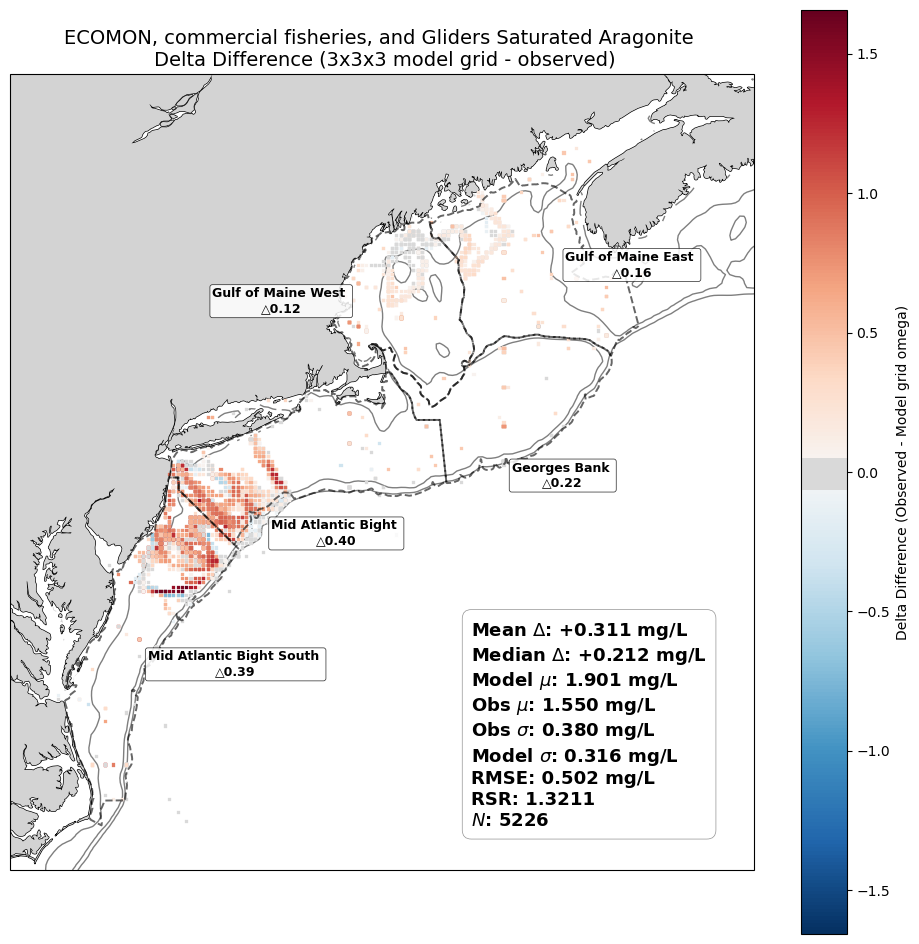

In [30]:
import numpy as np
import cartopy.crs as ccrs          # ccrs handles projections
import cartopy.feature as cfeature  # cfeature handles land, ocean, coastlines
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import pandas as pd
import geopandas as gpd
import xarray as xr
from shapely.ops import unary_union

#Final Function

def map_OA_delta_difference(csv_file, bathymetry_nc_path, metric_col, title):
    # 1. Load delta data and geospatial shapes
    final = pd.read_csv(csv_file)
    
    # Load shapefile (already known to be in EPSG:4326 via your snippet)
    shapefile = gpd.read_file('https://github.com/hsynan/READ-EDAB-Synan_hydrographic_climatologies/raw/refs/heads/main/data/shapefiles/NES_5REGIONS.zip')
    if shapefile.crs is None:
        shapefile.set_crs("epsg:4326", inplace=True)
    elif shapefile.crs != "epsg:4326":
        shapefile = shapefile.to_crs("epsg:4326")

    # Load MOM6 static depth / bathymetry
    ds_bathym = xr.open_dataset(bathymetry_nc_path)
    
    # Setup base figure
    fig = plt.figure(figsize=(12, 15))
    map_projection = ccrs.PlateCarree()
    ax = plt.axes(projection=map_projection)

    # 2. Dynamic Symmetric Colorbar Normalization (Centered perfectly at 0)
    max_dev = max(abs(final['delta_difference_grid'].min()), abs(final['delta_difference_grid'].max()))
    div_norm = mcolors.TwoSlopeNorm(vmin=-max_dev, vcenter=0.0, vmax=max_dev)
    base_rdbu=plt.cm.get_cmap('RdBu_r')(np.linspace(0, 1, 256))

    neg_bound_pct=div_norm(-0.05)
    pos_bound_pct=div_norm(0.05)

    idx_start = int(neg_bound_pct * 255)
    idx_end = int(pos_bound_pct * 255)

    base_rdbu[idx_start:idx_end+1] = [0.85, 0.85, 0.85, 1.0] 

    # Convert the modified color array back into a usable Matplotlib colormap
    yellow_center_rdbu = mcolors.ListedColormap(base_rdbu)


    # 3. Scatter Plot of Point Observations vs Grid Delta
    sc = ax.scatter(
        final['matched_lon'].astype(float), 
        final['matched_lat'].astype(float), 
        c=final['delta_difference_grid'], 
        cmap=yellow_center_rdbu, 
        norm=div_norm,
        s=5, 
        edgecolors= None, 
        linewidths=0.2, 
        transform=map_projection,
        zorder=3,
         marker='s'
    )

    cb = plt.colorbar(sc, shrink=0.8, label='Delta Difference (Observed - Model grid omega)')

# 4. OVERLAY: Bathymetry Contour Lines from MOM6 NetCDF
    lon_var = 'lonh' if 'lonh' in ds_bathym.variables else ('lon' if 'lon' in ds_bathym.variables else 'xh')
    lat_var = 'lath' if 'lath' in ds_bathym.variables else ('lat' if 'lat' in ds_bathym.variables else 'yh')

    # Extract raw 2D depth matrices and define target line thresholds
    depth_data = ds_bathym['deptho'].values
    contour_levels = [25, 150, 400]

    # Plot uncolored neutral gray contour line isobaths
    # FIX: Pass clip_path=ax.patch directly inside the contour function call
    bathym_contours = ax.contour(
        ds_bathym[lon_var], ds_bathym[lat_var], depth_data,
        levels=contour_levels,
        colors='#7f7f7f',       # Clean, uncolored neutral gray lines
        linewidths=1.0,         # Slim line weight
        linestyles='-',         # Solid contour lines
        transform=map_projection,
        clip_path=ax.patch,     # Forces exact clipping to map frame boundaries natively
        zorder=1
    )

    # Custom legend matching the clean line format
    depth_labels = ['Shallow Limit (25m)', 'Midshelf Limit (150m)', 'Shelf-Slope Limit (400m)']
    
    # Generate line handles for the legend matching our contour lines
    legend_lines = [
        plt.Line2D([0], [0], color='#7f7f7f', linewidth=1.0, linestyle='-', label=label)
        for label in depth_labels
    ]
    



    # 5. OVERLAY: Regional Shapefile Boundaries & Text Labels
    # Draw regional outlines
    shapefile.geometry.boundary.plot(
        ax=ax, 
        color='black', 
        linewidth=1.4, 
        linestyle='--', 
        alpha=0.6,
        transform=map_projection,
        zorder=10
    )

    # Define dictionary maps matching your shapefile index/id rows
    region_names = {0: "MAB_south", 1: "MAB_north", 2: "GB", 3: "GOM_west", 4: "GOM_east"}


    region_offsets = {
        "MAB_south":  {"lon": +1.8, "lat":  -0.4}, # Shift left and up slightly
        "MAB_north":  {"lon":  0.4, "lat": -1.1}, # Shift down slightly
        "GB":         {"lon":  1, "lat":  -1.1}, # Shift right and down
        "GOM_west":   {"lon": -2.4, "lat":  0.1}, # Shift left slightly
        "GOM_east":   {"lon":  1.9, "lat": 0.1}  # Shift right and down
    }

    regional_means = final.groupby('region')['delta_difference_grid'].mean().to_dict()

    for idx, row in shapefile.iterrows():
        name = region_names.get(idx, f"Region {region_names}")
        #display_text = name

        raw_name = region_names.get(idx, f"{idx}") 

        name_mapping={
            "MAB_south": "Mid Atlantic Bight South",
            "MAB_north": "Mid Atlantic Bight",
            "GB": "Georges Bank",
            "GOM_west": "Gulf of Maine West",
            "GOM_east": "Gulf of Maine East"
        }
        
        # Simply replace the underscore with a space
        #display_text = raw_name.replace('_', ' ')
        
        display_clean = name_mapping.get(raw_name, raw_name.replace('_', ' '))
        r_mean=regional_means.get(name, 0.0)
        display_text = f"{display_clean} \n△{r_mean:.2f}"
        
        # Get the default center coordinates
        centroid = row.geometry.centroid
        lon_pos = centroid.x
        lat_pos = centroid.y
        
        # CHANGED: Apply custom offset if the region exists in our dictionary
        if name in region_offsets:
            lon_pos += region_offsets[name]["lon"]
            lat_pos += region_offsets[name]["lat"]
        
        ax.text(
            lon_pos, lat_pos, display_text, # Using the adjusted coordinates
            color='black', fontsize=9, fontweight='bold',
            ha='center', va='center', transform=map_projection,
            bbox=dict(facecolor='white', alpha=0.85, edgecolor='black', linewidth=0.5, boxstyle='round,pad=0.2'),
            zorder=11
        )

    # 6. Map features and basemaps
    ax.add_feature(cfeature.COASTLINE, linewidth=1)
    ax.add_feature(cfeature.LAND, zorder=2, facecolor='lightgrey')
    
    # Set explicit spatial scope frame
    ax.set_extent([-77, -63, 34.5, 46], crs=ccrs.PlateCarree())
    ax.set_title(title, fontsize=14)

    # 7. Descriptive Stats Block Placement
    mean_delta = final['delta_difference_grid'].mean()
    median_delta = final['delta_difference_grid'].median()  
    total_pts = len(final['delta_difference_grid'].dropna())
    global_mean = final['cube_mean'].mean()
    obs_mean = final[metric_col].mean()   
    obs_std = final[metric_col].std()     
    
    global_variance = (final['cube_std']**2).mean() + final['cube_mean'].var()  
    global_std = np.sqrt(global_variance)
    global_rmse = np.sqrt((final['delta_difference_grid'] ** 2).mean())

    text_str = (
        f"Mean $\Delta$: {mean_delta:+.3f} mg/L\n"
        f"Median $\Delta$: {median_delta:+.3f} mg/L\n"
        f"Model $\mu$: {global_mean:.3f} mg/L\n"
        f"Obs $\mu$: {obs_mean:.3f} mg/L\n"
        f"Obs $\sigma$: {obs_std:.3f} mg/L\n"
        f"Model $\sigma$: {global_std:.3f} mg/L\n"
        f"RMSE: {global_rmse:.3f} mg/L\n"
        f"RSR: {(global_rmse / obs_std):.4f}\n"
        f"$N$: {total_pts}"
    )

    box_style = dict(boxstyle='round,pad=0.5', facecolor='white', alpha=0.85, edgecolor='gray', linewidth=0.5)
    ax.text(
        0.62, 0.05, 
        text_str, 
        transform=ax.transAxes, 
        fontsize=13, 
        fontweight='bold',
        va='bottom', 
        ha='left', 
        bbox=box_style,
        zorder=105 
    )

    plt.show()

# Execution Syntax
csv_path = r"C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026\data\Processed_Data\comparison\complete\OA_MOM6_3x3x3_comparison_classified.csv"
csv_path2=r"C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026\data\Processed_Data\comparison\complete\CONCAT_MOM6_3x3x3_comparison_classified.csv"
bathymetry_path = r"C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026\data\Bathymetry\MOM6_hindcast_ocean_static_deptho.nc"

map_OA_delta_difference(csv_path, bathymetry_path, 'saturated_aragonite', 'ECOMON, commercial fisheries, and Gliders Saturated Aragonite \n Delta Difference (3x3x3 model grid - observed)')